# INF-8239 · Trabajo final · Clasificación de tickets de soporte

**Modalidad A (proyecto aplicado) · Tema 13 · individual.** Pregunta: ¿con qué exactitud se puede predecir la cola de un ticket a partir de su asunto y su cuerpo, y es suficiente para apoyar el triaje? El artefacto práctico es una aplicación que propone cola y prioridad; la persona decide.

| Elemento | Definición |
|---|---|
| Decisor | Coordinador/a de triaje de la mesa de ayuda |
| Datos | Tickets públicos de Hugging Face (CC BY-NC 4.0), probablemente sintéticos; ningún dato de organizaciones reales |
| Entrada | Asunto + cuerpo (se excluyen campos que se llenan después del triaje) |
| Modelos | B0 mayoritaria, B1 Naive Bayes, M1 regresión logística, M2 logística balanceada |
| Decisión | Modos con abstención (sugerencia / top-3 / triaje manual) + prioridad con reglas que solo suben |

In [1]:
import json, os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
print(Path.cwd())

/home/claude/TF/INF8239_TF_DSS_Tickets


## 1. Datos y auditoría

In [2]:
!python scripts/download_data.py
!python scripts/audit_data.py

OK 25e91530-dataset-tickets-multi-lang-4-20k.csv 9be3bf810584fe01


{
 "rows_raw": 20000,
 "rows_after_cleaning": 19999,
 "language": {
  "en": 11922,
  "de": 8077
 },
 "post_triage_fields_accuracy": {
  "tags_y_tipo": 0.39275,
  "respuesta_agente": 0.40875
 },
 "majority_class_accuracy": 0.2912145607280364
}


{
 "rows_raw": 20000,
 "rows_after_cleaning": 19999,
 "nulls": {
  "subject": 1461,
  "body": 2,
  "answer": 4,
  "tag_2": 46,
  "tag_3": 95,
  "tag_4": 1539,
  "tag_5": 6909,
  "tag_6": 12649,
  "tag_7": 16072,
  "tag_8": 18093
 },
 "language": {
  "en": 11922,
  "de": 8077
 },
 "language_label_vs_detected": {
  "de->de": 5966,
  "de->en": 2111,
  "en->de": 3,
  "en->en": 11919
 },
 "post_triage_fields_accuracy": {
  "tags_y_tipo": 0.39275,
  "respuesta_agente": 0.40875
 },
 "majority_class_accuracy": 0.2912145607280364
}


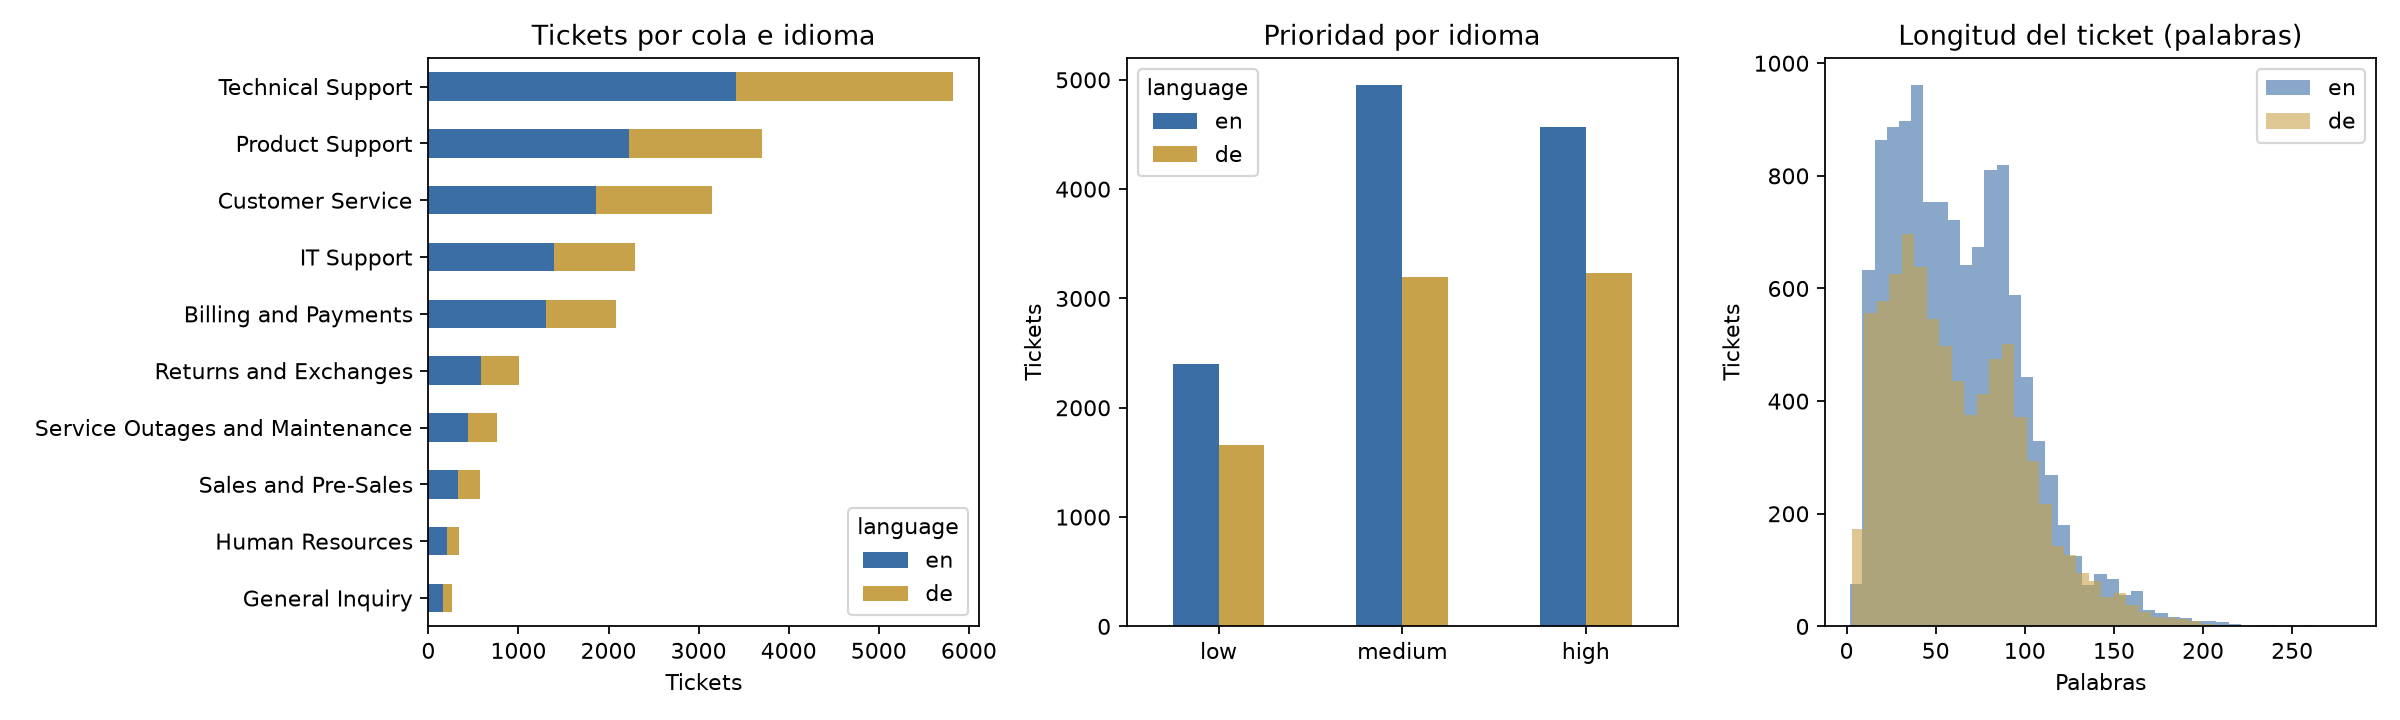

In [3]:
audit = json.loads(Path("reports/audit_summary.json").read_text())
print(json.dumps({k: audit[k] for k in ["rows_raw", "rows_after_cleaning", "nulls", "language", "language_label_vs_detected",
                                        "post_triage_fields_accuracy", "majority_class_accuracy"]}, indent=1, ensure_ascii=False))
display(Image("reports/fig_audit.png", width=1000))

**Lectura.** Las colas están desbalanceadas, una cuarta parte de los tickets marcados como alemán están en inglés y los campos posteriores al triaje se excluyen porque no existen al decidir. Su poder predictivo es moderado (≈ 0.40), así que excluirlos no esconde un atajo fácil.

## 2. Modelos, evaluación y artefacto práctico (≈ 5 min en CPU)

In [4]:
!python scripts/train_evaluate.py
!python scripts/update_cards.py

Partición: {'removed_near_dup_valid': 104, 'near_dup_label_conflicts_valid': 0, 'removed_near_dup_test': 99, 'near_dup_label_conflicts_test': 1, 'train': 13999, 'valid': 2896, 'test': 2901}


valid {'model': 'dummy', 'accuracy': 0.292817679558011, 'f1_macro': 0.0452991452991453, 'top3_accuracy': 0.4088397790055249, 'train_seconds': 1.4551405049999744}


valid {'model': 'nb', 'accuracy': 0.4302486187845304, 'f1_macro': 0.337167672394825, 'top3_accuracy': 0.710635359116022, 'train_seconds': 1.5967699600000174}


valid {'model': 'logreg_C2', 'accuracy': 0.4416436464088398, 'f1_macro': 0.3016643499852857, 'top3_accuracy': 0.7890193370165746, 'train_seconds': 20.578804407000007}


valid {'model': 'logreg_C5', 'accuracy': 0.4599447513812155, 'f1_macro': 0.3597646246119754, 'top3_accuracy': 0.7973066298342542, 'train_seconds': 30.36207628300002}


valid {'model': 'logreg_C10', 'accuracy': 0.4630524861878453, 'f1_macro': 0.38399828542308334, 'top3_accuracy': 0.794889502762431, 'train_seconds': 25.05257409699999}


valid {'model': 'logreg_C5_bal', 'accuracy': 0.4381906077348066, 'f1_macro': 0.4231204641750247, 'top3_accuracy': 0.7703729281767956, 'train_seconds': 19.08894583}


                                           model  accuracy  f1_macro  top3_accuracy  acc_ci_low  acc_ci_high  top3_ci_low  top3_ci_high  train_seconds  latency_ms  size_mb  selected
                            B0 Clase mayoritaria     0.291     0.045          0.407       0.274        0.308        0.390         0.426          1.455       0.410    0.542     False
                                B1 Complement NB     0.426     0.331          0.714       0.408        0.445        0.698         0.730          1.597       1.124    5.487     False
              M1 Regresión logística (logreg_C2)     0.437     0.291          0.787       0.419        0.455        0.771         0.802         20.579       0.544    3.810      True
M2 Logística con pesos balanceados (alternativa)     0.442     0.426          0.775       0.424        0.460        0.759         0.790         19.089       0.583    3.810     False
{
 "thresholds": {
  "t_strong": 0.5612247858109364,
  "t_top3": 0.7208734856007891,
  "st

MODEL_CARD.md actualizado


{'removed_near_dup_valid': 104, 'near_dup_label_conflicts_valid': 0, 'removed_near_dup_test': 99, 'near_dup_label_conflicts_test': 1, 'train': 13999, 'valid': 2896, 'test': 2901}


,model,accuracy,f1_macro,top3_accuracy,train_seconds
0,dummy,0.293,0.045,0.409,1.455
1,nb,0.430,0.337,0.711,1.597
2,logreg_C2,0.442,0.302,0.789,20.579
3,logreg_C5,0.460,0.360,0.797,30.362
4,logreg_C10,0.463,0.384,0.795,25.053
5,logreg_C5_bal,0.438,0.423,0.770,19.089


,model,key,accuracy,f1_macro,top3_accuracy,acc_ci_low,acc_ci_high,top3_ci_low,top3_ci_high,train_seconds,latency_ms,size_mb,selected
0,B0 Clase mayoritaria,dummy,0.291,0.045,0.407,0.274,0.308,0.390,0.426,1.455,0.410,0.542,False
1,B1 Complement NB,nb,0.426,0.331,0.714,0.408,0.445,0.698,0.730,1.597,1.124,5.487,False
2,M1 Regresión logística (logreg_C2),logreg_C2,0.437,0.291,0.787,0.419,0.455,0.771,0.802,20.579,0.544,3.810,True
3,M2 Logística con pesos balanceados (alternativa),logreg_C5_bal,0.442,0.426,0.775,0.424,0.460,0.759,0.790,19.089,0.583,3.810,False


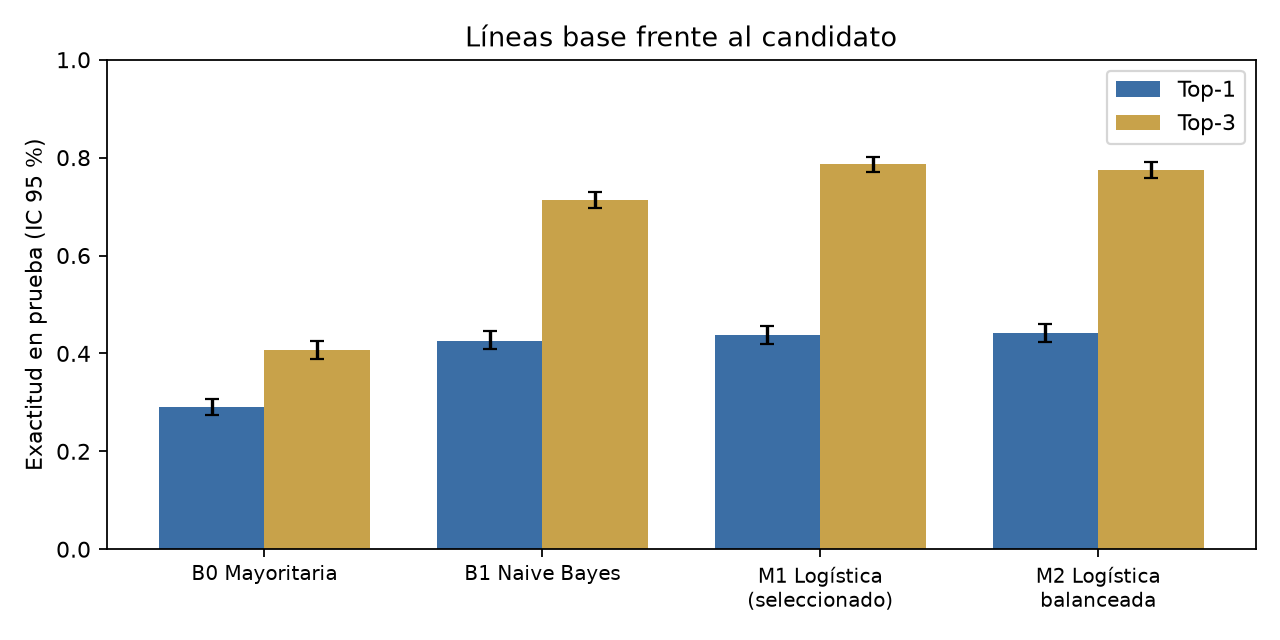

In [5]:
print(json.loads(Path("reports/split.json").read_text()))
display(pd.read_csv("reports/validation_models.csv").round(3))
display(pd.read_csv("reports/test_models.csv").drop(columns=["sha256"]).round(3))
display(Image("reports/fig_models.png", width=750))

## 3. Utilidad para la persona decisora

Umbrales: {'t_strong': 0.5612247858109364, 't_top3': 0.7208734856007891, 'strong_target': 0.75, 'top3_target': 0.85, 'min_support': 200}
{
 "n": 2901,
 "share_sugerencia": 0.15305067218200621,
 "accuracy_sugerencia": 0.7477477477477478,
 "share_top3": 0.432609445018959,
 "hit_top3_mode": 0.8334661354581673,
 "share_triaje_manual": 0.41433988279903483,
 "correct_option_available": 0.889348500517063,
 "high_to_low_rate_model": 0.0338680926916221,
 "high_to_low_rate_dss": 0.030303030303030304,
 "high_recall_model": 0.5962566844919787,
 "high_recall_dss": 0.6470588235294118,
 "priority_accuracy_model": 0.520854877628404,
 "priority_accuracy_dss": 0.5143054119269217,
 "rules_fire_rate": 0.1368493622888659
}


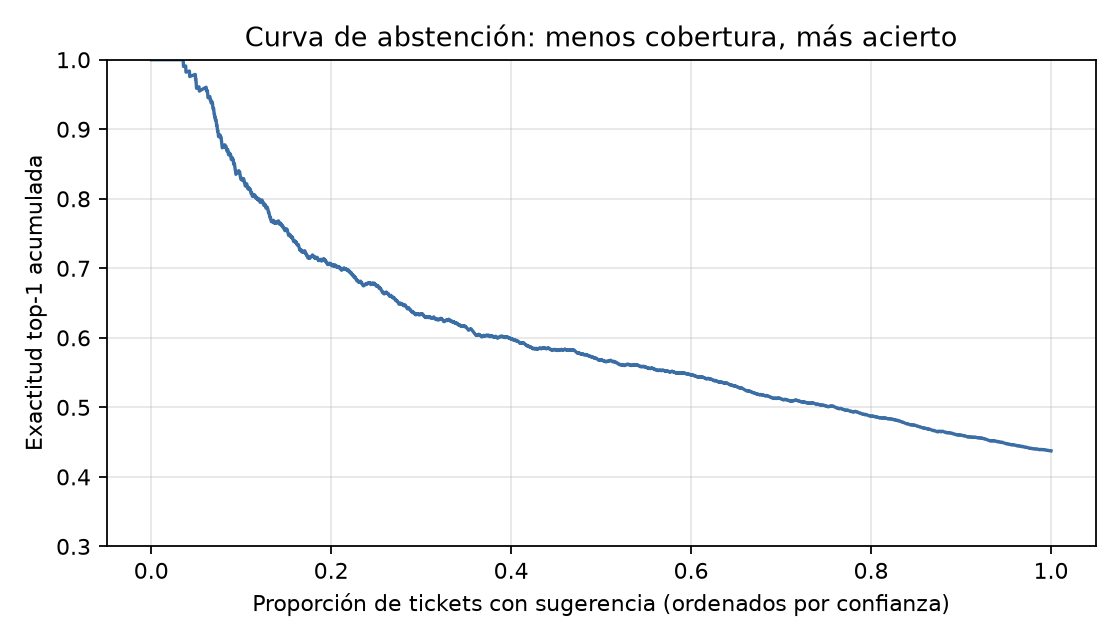

,ticket_id,language,language_detected,queue,priority,mode,queue_1,queue_2,queue_3,conf_1,conf_top3,priority_model,priority_suggested,rules_fired
0,16028,en,en,Technical Support,low,triaje_manual,Product Support,Technical Support,Billing and Payments,0.319037,0.719482,medium,medium,NaN
1,8777,en,en,Product Support,medium,top3,Product Support,Returns and Exchanges,Technical Support,0.392460,0.725708,medium,medium,NaN
2,19116,en,en,Customer Service,low,top3,Customer Service,Technical Support,IT Support,0.550298,0.861659,low,low,NaN
3,19865,de,de,Returns and Exchanges,low,triaje_manual,Customer Service,Product Support,Technical Support,0.390315,0.647590,medium,medium,NaN
4,3502,de,en,Billing and Payments,high,sugerencia,Billing and Payments,IT Support,Product Support,0.666805,0.817250,high,high,NaN
5,10761,de,de,Product Support,medium,triaje_manual,IT Support,Product Support,Technical Support,0.216672,0.558283,medium,medium,NaN
6,15572,de,de,Customer Service,medium,triaje_manual,Customer Service,Technical Support,Product Support,0.479834,0.708136,medium,medium,NaN
7,15760,en,en,Billing and Payments,high,triaje_manual,Customer Service,Billing and Payments,Technical Support,0.385868,0.676679,medium,medium,NaN
8,4870,de,en,Technical Support,high,sugerencia,Technical Support,Customer Service,Product Support,0.634567,0.838856,high,high,NaN
9,716,de,de,IT Support,medium,sugerencia,Technical Support,Product Support,Customer Service,0.652166,0.820766,high,high,NaN


In [6]:
r = json.loads(Path("reports/results.json").read_text())
print("Umbrales:", r["thresholds"]); print(json.dumps(r["dss_test"], indent=1))
display(Image("reports/fig_abstention.png", width=650))
display(pd.read_csv("reports/test_recommendations.csv").head(10))

## 4. Subgrupos, errores y puertas

by_language.csv


,language,n,accuracy,top3,triaje_manual,sugerencia
0,de,1208,0.400,0.756,0.503,0.108
1,en,1693,0.464,0.809,0.351,0.185


by_language_detected.csv


,lang_group,n,accuracy,top3,triaje_manual,sugerencia
0,de→de,914,0.392,0.739,0.539,0.085
1,de→en,294,0.425,0.810,0.391,0.180
2,en→de,1,0.000,1.000,0.000,0.000
3,en→en,1692,0.465,0.809,0.351,0.185


by_queue.csv


...

by_priority.csv


,priority,n,accuracy,top3
0,high,1122,0.508,0.825
1,low,609,0.373,0.719
2,medium,1170,0.403,0.785


top_confusions.csv


,real,predicha,errores,% de la cola real
0,Product Support,Technical Support,254,0.474
1,IT Support,Technical Support,187,0.560
2,Customer Service,Technical Support,171,0.371
3,Technical Support,Product Support,97,0.115
4,Customer Service,Product Support,81,0.176
5,Technical Support,Customer Service,79,0.093
6,Product Support,Customer Service,76,0.142
7,Returns and Exchanges,Technical Support,63,0.426


IC 95 % de brechas de idioma: {'top3_en_minus_de': [0.02232377035553483, 0.08381334028312921], 'acc_en_minus_de': [0.02799153751520676, 0.09916213723825802], 'top3_detected_en_minus_de': [0.035414912584815016, 0.10305639476334344]}
McNemar NB vs candidato: {'only_a': 224, 'only_b': 257, 'p_value': 0.14446615420739686}
Recall top-3 medio por cola: {'dummy': 0.3, 'nb': 0.663, 'logreg_C2': 0.53, 'logreg_C5_bal': 0.67}


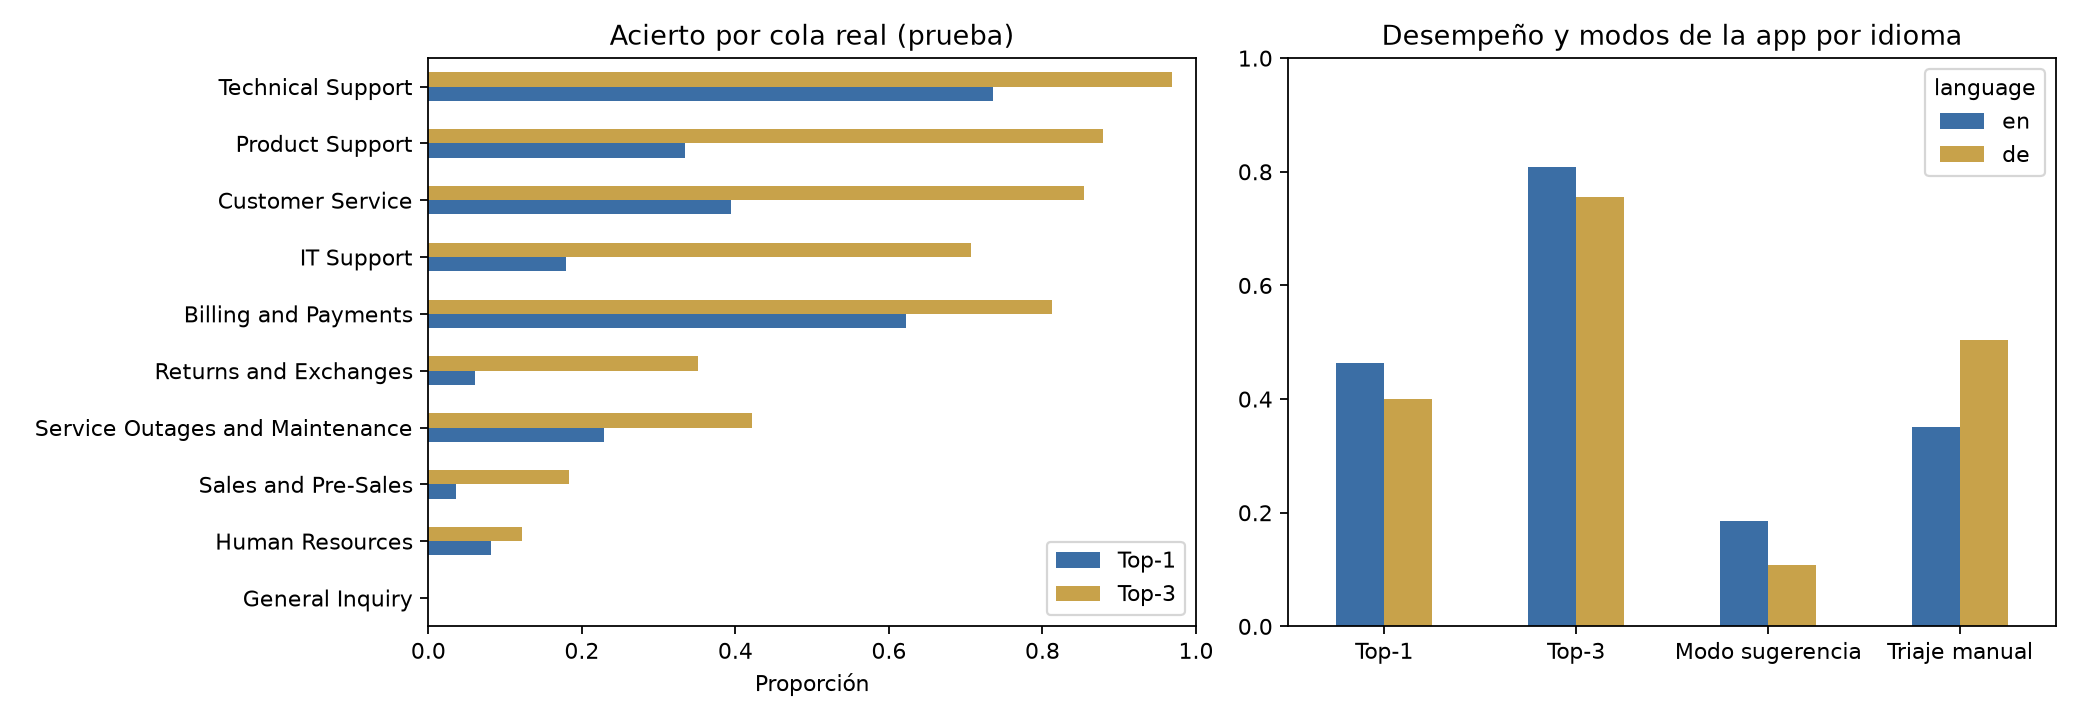

,ticket_id,language,queue,pred,conf,priority,top_terms,excerpt
0,8961,en,Product Support,Technical Support,0.788099,medium,"data system, access attempt, attempt has, in medical, system",Detection of Unauthorized Access Attempt in Medical Data System An unauthorized access attempt has been detected in ...
1,16829,de,Customer Service,Product Support,0.776344,low,"campaign, and weak, media campaign, results, engagement",Support for Campaign Issues A new social media campaign is experiencing low engagement and weak brand awareness. Aft...
2,5376,de,Product Support,Technical Support,0.758685,medium,"evernote, knime, js, attempted to, canvas","Trouble with Data Violations A data violation has occurred, which might be due to outdated KNIME. I have attempted t..."
3,10979,en,Billing and Payments,Customer Service,0.740589,low,"analytics services, data, investment, investments, services",Enquiry about Data Analytics Services I am interested in learning about your data analytics services to optimize my ...
4,2102,en,Service Outages and Maintenance,Technical Support,0.738984,medium,"website, website analytics, code, in website, and we","Technical Glitch in Website Analytics Greetings, I am correspondencing to inform you about a technical glitch with o..."
5,8229,de,IT Support,Technical Support,0.738118,medium,"recent update, server, logs, problem by, what additional",I am encountering logging problems after the recent update. The issue likely originates from a configuration mismatc...
6,14438,de,Returns and Exchanges,Technical Support,0.727584,low,"server, versucht die, versucht, ihre hilfe, dafür","Benachrichtigung über Datensperren und Sicherheitsungleichgewichte Sehr geehrte Kundenservice, wir möchten Sie über ..."
7,3793,en,Technical Support,Customer Service,0.695107,high,"analytics services, investment, data, optimization could, any information",Request for Information on Data Analytics Services for Investment Optimization Could you provide more details on the...
8,12448,en,IT Support,Technical Support,0.691637,high,"rebooting, changes in, configurations, vpn, software updates","Problem with VPN Our marketing agency is facing connectivity issues with the VPN-Router, which is affecting our digi..."
9,423,en,Returns and Exchanges,Technical Support,0.691137,medium,"application, recent updates, with project, software, connectivity issues","Issue with Project Management Software An error has been encountered with the project management software, which is ..."


Puertas: {'top3_accuracy': False, 'language_gap_top3': True, 'language_gap_top3_detected': True, 'high_to_low_rate': True, 'latency': True, 'model_size': True} → REVISAR


In [7]:
for f in ["by_language.csv", "by_language_detected.csv", "by_queue.csv", "by_priority.csv", "top_confusions.csv"]:
    print(f); display(pd.read_csv(f"reports/{f}").round(3))
print("IC 95 % de brechas de idioma:", r["language_gap_ci95"])
print("McNemar NB vs candidato:", r["mcnemar_nb_vs_candidate"])
print("Recall top-3 medio por cola:", {k: round(v, 3) for k, v in r["macro_recall_top3_by_queue"].items()})
display(Image("reports/fig_subgroups.png", width=1000))
display(pd.read_csv("reports/error_sample_30.csv"))
print("Puertas:", r["gates"], "→", r["gates_status"])

## 5. Pruebas

In [8]:
!python -m pytest -q

...

......

...

......

.                                                      [100%]
19 passed in 3.05s


## 6. Conclusión
El candidato supera con claridad a ambas líneas base en top-3, pero no alcanza la puerta de 0.80 y deja desatendidas las colas pequeñas. Además, los tickets en alemán reciben menos sugerencias directas y más triaje manual. Como DSS, la abstención mantiene la opción correcta disponible para la persona en ≈ 89 % de los casos. **Decisión propuesta: LIMITAR** a un piloto supervisado. Queda pendiente que la estudiante ratifique los valores (objetivos, reglas, puertas) y elija entre M1 (acierto global) y M2 (colas pequeñas).

In [9]:
print(json.dumps(r['environment'], indent=1))

{
 "python": "3.12.13",
 "platform": "Linux-6.18.44-fc-v153-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "scikit_learn": "1.9.1",
 "pandas": "2.3.3",
 "numpy": "2.5.3"
}
